In [ ]:
import sys
!{sys.executable} -m pip install -U ydata-profiling[notebook]
!pip install jupyter-contrib-nbextensions
!pip install recordlinkage

In [448]:
import pandas as pd
import numpy as np
import re
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import plotly.express as px
from ydata_profiling import ProfileReport
import recordlinkage

In [449]:
# Loading the dataset

DATASET = pd.read_csv('italian/Comune-di-Milano-Strutture-ricettive-alberghiere.csv',sep=';',encoding='unicode_escape')
DATASET

,Ubicazione,Tipo via,Descrizione via,Civico,Codice via,ZD,Camere,Camere piano,Categoria,Insegna,Piani totali,Piano piano,Posti letto,Posti letto per piano,Tipo attività struture extra
0,ALZ NAVIGLIO GRANDE N. 8 (z.d. 6),ALZ,NAVIGLIO GRANDE,8.0,5144.0,6.0,14.0,NaN,4,HOTEL MAISON BORELLA,NaN,NaN,25.0,NaN,Albergo
1,codvia 0000 num.024 ; (),NaN,NaN,NaN,NaN,NaN,259.0,259,4,radisson blu hotel milan,NaN,NaN,518.0,518,Albergo
2,CSO BUENOS AIRES N. 18 (z.d. 3),CSO,BUENOS AIRES,18.0,2129.0,3.0,16.0,16,1,hotel aurora,1.0,1,25.0,25,Albergo
3,CSO BUENOS AIRES N. 26 (z.d. 3),CSO,BUENOS AIRES,26.0,2129.0,3.0,25.0,NaN,3,hotel buenos aires,NaN,NaN,39.0,NaN,Albergo
4,CSO BUENOS AIRES N. 2 (z.d. 3),CSO,BUENOS AIRES,2.0,2129.0,3.0,46.0,15;11;8,3,albergo fenice,4.0,1;2;3;4,98.0,24;19;13,Albergo
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
446,VLE TUNISIA N. 6 (z.d. 3),VLE,TUNISIA,6.0,2121.0,3.0,13.0,16,1,hotel kennedy,1.0,6,23.0,23,Albergo
447,VLE TUNISIA N. 9 (z.d. 3),VLE,TUNISIA,9.0,2121.0,3.0,50.0,3;6;9;9;9,4,st. george hotel,NaN,A;1;2;3;4,99.0,5;16;26;26;26,Albergo
448,VLE VITTORIO VENETO N. 30 (z.d. 2),VLE,VITTORIO VENETO,30.0,2107.0,2.0,15.0,NaN,2,hotel casa mia,NaN,NaN,25.0,NaN,Albergo
449,VLE ZARA N. 1 (z.d. 9),VLE,ZARA,1.0,1170.0,9.0,32.0,NaN,4,casa albergo residence zara lagosta,NaN,NaN,64.0,NaN,Residence


# Data Quality Assessment & Data Profiling

In [450]:
# Exploring the data

print(f"Shape of dataset: {DATASET.shape}\n\nColumns: {DATASET.columns}\n\nData types:\n{DATASET.dtypes}")

Shape of dataset: (451, 15)

Columns: Index(['Ubicazione', 'Tipo via', 'Descrizione via', 'Civico', 'Codice via',
       'ZD', 'Camere', 'Camere piano', 'Categoria', 'Insegna', 'Piani totali',
       'Piano piano', 'Posti letto', 'Posti letto per piano',
       'Tipo attività struture extra'],
      dtype='object')

Data types:
Ubicazione                       object
Tipo via                         object
Descrizione via                  object
Civico                          float64
Codice via                      float64
ZD                              float64
Camere                          float64
Camere piano                     object
Categoria                        object
Insegna                          object
Piani totali                    float64
Piano piano                      object
Posti letto                     float64
Posti letto per piano            object
Tipo attività struture extra     object
dtype: object


In [451]:
# Duplicated data

DUPLICATES = DATASET.duplicated()
print(f"Number of duplicated items: {DUPLICATES.sum()}")

Number of duplicated items: 0


In [452]:
# Completeness

print(f"Completeness evalutation for each column:")
for col in DATASET.columns:
  NULL = DATASET[col].isnull().sum()
  NOT_NULL = DATASET[col].count()
  COMPLETENESS = NOT_NULL / (NOT_NULL + NULL)
  COMPLETENESS = '{0:.1f}%'.format(COMPLETENESS*100)
  print(f"\t{col}: {COMPLETENESS}")
NULL = DATASET.isnull().sum().sum()
NOT_NULL = DATASET.count().sum().sum()
COMPLETENESS = NOT_NULL / (NOT_NULL + NULL)
COMPLETENESS = '{0:.1f}%'.format(COMPLETENESS*100)
print(f"\nTotal completeness evaluation: {COMPLETENESS}")

Completeness evalutation for each column:
	Ubicazione: 100.0%
	Tipo via: 96.9%
	Descrizione via: 96.9%
	Civico: 93.3%
	Codice via: 96.9%
	ZD: 96.9%
	Camere: 99.8%
	Camere piano: 76.5%
	Categoria: 98.4%
	Insegna: 97.8%
	Piani totali: 41.5%
	Piano piano: 44.1%
	Posti letto: 99.8%
	Posti letto per piano: 76.5%
	Tipo attività struture extra: 97.8%

Total completeness evaluation: 87.5%


In [453]:
# Accuracy for 'ZD' column, assumption is that its value belong to {1, ..., 9} set.

CORRECT = sum(1 for item in DATASET['ZD'] if item in range(1, 10))
NOT_NULL = DATASET['ZD'].count()
ACCURACY = CORRECT / NOT_NULL
ACCURACY = '{0:.1f}%'.format(ACCURACY*100)
print(f"Accuracy evaluation for 'ZD' column: {ACCURACY}")

Accuracy evaluation for 'ZD' column: 100.0%


In [454]:
# Distinctness

print(f"Distinctness evaluation for each column:")
for col in DATASET.columns:
  DISTINCTNESS = DATASET[col].nunique() / DATASET[col].count()
  DISTINCTNESS = '{0:.1f}%'.format(DISTINCTNESS*100)
  print(f"\t{col}: {DISTINCTNESS}")

Distinctness evaluation for each column:
	Ubicazione: 97.1%
	Tipo via: 1.8%
	Descrizione via: 68.6%
	Civico: 21.4%
	Codice via: 69.1%
	ZD: 2.1%
	Camere: 32.9%
	Camere piano: 60.0%
	Categoria: 1.8%
	Insegna: 99.1%
	Piani totali: 5.9%
	Piano piano: 29.1%
	Posti letto: 43.6%
	Posti letto per piano: 63.5%
	Tipo attività struture extra: 0.7%


In [455]:
# Consistency for columns regarding the address columns:
# information contained in 'Ubicazione' column is splitted into
# 'Tipo via', 'Descrizione via', 'Civico', 'ZD' columns.

TIPO_VIA = DATASET['Ubicazione'].str.split(' ').str[0]
regex = r"^[A-ZÀ-Ù]+\s+(.*?)\s+[Nn][\.\°]?\s*\d+"
NOME_VIA = DATASET['Ubicazione'].str.extract(regex)[0]
regex = r"[Nn]\.\s(\d+)"
CIVICO = DATASET['Ubicazione'].str.extract(regex)[0]
CIVICO = pd.to_numeric(CIVICO, errors='coerce')
regex = r"z\.d\.\s(\d+)"
ZD = DATASET['Ubicazione'].str.extract(regex)[0]
ZD = pd.to_numeric(ZD, errors='coerce')

CONSISTENCY = np.where(TIPO_VIA == DATASET['Tipo via'], 1, 0).sum()
CONSISTENCY = CONSISTENCY / (DATASET['Tipo via'].notna() & TIPO_VIA.notna()).sum()
CONSISTENCY = '{0:.1f}%'.format(CONSISTENCY*100)
print(f"Consistency evaluation for 'Ubicazione' column: {CONSISTENCY}")

CONSISTENCY = np.where(NOME_VIA == DATASET['Descrizione via'], 1, 0).sum()
CONSISTENCY = CONSISTENCY / (DATASET['Descrizione via'].notna() & NOME_VIA.notna()).sum()
CONSISTENCY = '{0:.1f}%'.format(CONSISTENCY*100)
print(f"Consistency evaluation for 'Descrizione via' column: {CONSISTENCY}")

CONSISTENCY = np.where(CIVICO == DATASET['Civico'], 1, 0).sum()
CONSISTENCY = CONSISTENCY / (DATASET['Civico'].notna() & CIVICO.notna()).sum()
CONSISTENCY = '{0:.1f}%'.format(CONSISTENCY*100)
print(f"Consistency evaluation for 'Civico' column: {CONSISTENCY}")

CONSISTENCY = np.where(ZD == DATASET['ZD'], 1, 0).sum()
CONSISTENCY = CONSISTENCY / (DATASET['ZD'].notna() & ZD.notna()).sum()
CONSISTENCY = '{0:.1f}%'.format(CONSISTENCY*100)
print(f"Consistency evaluation for 'ZD' column: {CONSISTENCY}")

Consistency evaluation for 'Ubicazione' column: 100.0%
Consistency evaluation for 'Descrizione via' column: 100.0%
Consistency evaluation for 'Civico' column: 99.8%
Consistency evaluation for 'ZD' column: 98.6%


In [456]:
# Consistency for columns regarding the number of rooms:
# the total number should be the sum of all rooms per floor.

ROOMS = (DATASET["Camere piano"]
         .fillna("")
         .apply(lambda x: (sum(float(v)for v in x.split(';') if v.strip() != "") if x.strip() != "" else np.nan)))
CONSISTENCY = np.where(DATASET['Camere'] == ROOMS, 1, 0).sum()
CONSISTENCY = CONSISTENCY / (DATASET['Camere'].notna() & ROOMS.notna()).sum()
CONSISTENCY = '{0:.1f}%'.format(CONSISTENCY*100)
print(f"Consistency evaluation for 'Camere' column: {CONSISTENCY}")

Consistency evaluation for 'Camere' column: 31.3%


In [457]:
# Consistency for columns regarding the number of beds:
# the total number should be the sum of all beds per floor.

BEDS = (DATASET['Posti letto per piano']
        .fillna("")
        .apply(lambda x: (sum(float(v) for v in x.split(';') if v.strip() != "") if x.strip() != "" else np.nan)))
CONSISTENCY = np.where(DATASET['Posti letto'] == BEDS, 1, 0).sum()
CONSISTENCY = CONSISTENCY / (DATASET['Posti letto'].notna() & BEDS.notna()).sum()
CONSISTENCY = '{0:.1f}%'.format(CONSISTENCY*100)
print(f"Consistency evaluation for 'Posti letto' column: {CONSISTENCY}")

Consistency evaluation for 'Posti letto' column: 26.4%


In [458]:
# Consistency for 'Piano piano' columns:
# the number of values should correspond to the total number of floors.

FLOORS = DATASET['Piano piano'].str.split(';')
FLOORS = FLOORS.apply(lambda x: len(x) if isinstance(x, list) else 0)
CONSISTENCY = np.where(FLOORS == DATASET['Piani totali'], 1, 0).sum()
CONSISTENCY = CONSISTENCY / (DATASET['Piani totali'].notna() & FLOORS.notna()).sum()
CONSISTENCY = '{0:.1f}%'.format(CONSISTENCY*100)
print(f"Consistency evaluation for 'Piano piano' column: {CONSISTENCY}")

Consistency evaluation for 'Piano piano' column: 83.4%


In [459]:
# Correlation

ONLYNUMBERS = list(DATASET.select_dtypes(include=['float64']).columns)
CORRELATION = DATASET[ONLYNUMBERS].corr(method='pearson')
CORRELATION

,Civico,Codice via,ZD,Camere,Piani totali,Posti letto
Civico,1.000000,0.052579,0.037795,-0.035578,-0.080438,-0.032137
Codice via,0.052579,1.000000,0.608274,-0.080578,-0.159560,-0.078936
ZD,0.037795,0.608274,1.000000,0.060257,-0.147236,0.076507
Camere,-0.035578,-0.080578,0.060257,1.000000,0.607333,0.981215
Piani totali,-0.080438,-0.159560,-0.147236,0.607333,1.000000,0.588873
Posti letto,-0.032137,-0.078936,0.076507,0.981215,0.588873,1.000000


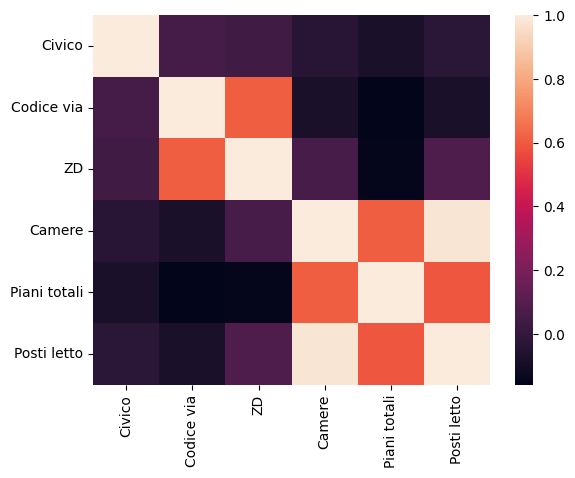

In [460]:
sns.heatmap(CORRELATION)
plt.show()

In [461]:
# Data distribution

DATASET.describe()

,Civico,Codice via,ZD,Camere,Piani totali,Posti letto
count,421.000000,437.000000,437.000000,450.000000,187.000000,450.000000
mean,126.061758,3105.935927,4.075515,60.002222,4.614973,114.128889
std,2026.885920,2140.700197,2.607553,70.441133,2.482496,141.013548
min,1.000000,1.000000,1.000000,7.000000,1.000000,7.000000
25%,7.000000,1510.000000,2.000000,16.000000,3.000000,25.000000
50%,16.000000,2250.000000,3.000000,32.000000,4.000000,60.000000
75%,33.000000,5097.000000,7.000000,72.000000,6.000000,137.250000
max,41609.000000,7505.000000,9.000000,439.000000,17.000000,922.000000


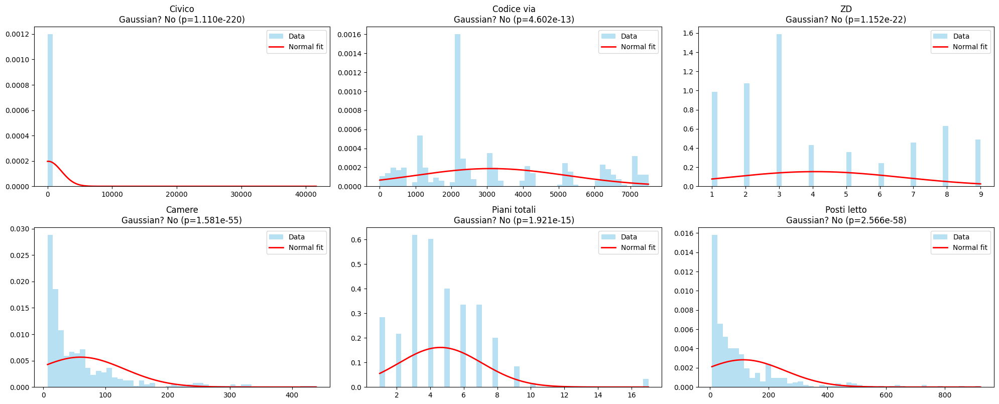

In [462]:
cols_per_row = 3
num_features = len(DATASET[ONLYNUMBERS])
rows = int(np.ceil(num_features / cols_per_row))
fig, axes = plt.subplots(rows, cols_per_row, figsize=(20, 4 * rows))
axes = axes.flatten()

for i, col in enumerate(DATASET[ONLYNUMBERS]):
    data = DATASET[col].dropna()
    ax = axes[i]

    # Histogram
    ax.hist(data, bins=50, density=True, alpha=0.6, color='skyblue', label='Data')

    # Gaussian fit
    xs = np.linspace(data.min(), data.max(), 200)
    fit = stats.norm.pdf(xs, np.mean(data), np.std(data))
    ax.plot(xs, fit, 'r-', lw=2, label='Normal fit')

    # Normality test
    stat, p = stats.normaltest(data)
    gaussian = 'Yes' if p > 0.05 else 'No'

    # Title
    ax.set_title(f"{col}\nGaussian? {gaussian} (p={p:.3e})")
    ax.legend()

# Removing unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [463]:
fig = px.box(DATASET[ONLYNUMBERS], y = DATASET[ONLYNUMBERS].columns)
fig.show()

In [464]:
# Profile report

PROFILE = ProfileReport(DATASET, title="Report")
PROFILE

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 15/15 [00:00<00:00, 33.65it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

# Data Cleaning

## Data transformation & standardization

In [465]:
DATASET.columns

Index(['Ubicazione', 'Tipo via', 'Descrizione via', 'Civico', 'Codice via',
       'ZD', 'Camere', 'Camere piano', 'Categoria', 'Insegna', 'Piani totali',
       'Piano piano', 'Posti letto', 'Posti letto per piano',
       'Tipo attività struture extra'],
      dtype='object')

In [466]:
# Standardization for columns' name

DATASET = DATASET.rename(columns={'Tipo via': 'TipoVia', 'Descrizione via': 'NomeVia', 'Codice via': 'CodiceVia', 'Camere piano': 'CamerePerPiano', 'Piani totali': 'PianiTotali', 'Piano piano': 'ListaPiani', 'Posti letto': 'PostiLetto', 'Posti letto per piano': 'PostiLettoPerPiano', 'Tipo attività struture extra': 'TipoStruttura'})

In [467]:
DATASET['TipoVia'].unique()

array(['ALZ', nan, 'CSO', 'GLL', 'LGO', 'PLE', 'PZA', 'VIA', 'VLE'],
      dtype=object)

In [468]:
# Replacing TipoVia abbreviations with their respective complete word

DATASET.loc[DATASET['TipoVia'] == 'ALZ', 'TipoVia'] = 'ALZAIA'
DATASET.loc[DATASET['TipoVia'] == 'CSO', 'TipoVia'] = 'CORSO'
DATASET.loc[DATASET['TipoVia'] == 'GLL', 'TipoVia'] = 'GALLERIA'
DATASET.loc[DATASET['TipoVia'] == 'LGO', 'TipoVia'] = 'LARGO'
DATASET.loc[DATASET['TipoVia'] == 'PLE', 'TipoVia'] = 'PIAZZALE'
DATASET.loc[DATASET['TipoVia'] == 'PZA', 'TipoVia'] = 'PIAZZA'
DATASET.loc[DATASET['TipoVia'] == 'VIA', 'TipoVia'] = 'VIA'
DATASET.loc[DATASET['TipoVia'] == 'VLE', 'TipoVia'] = 'VIALE'

In [469]:
DATASET['TipoStruttura'].unique()

array(['Albergo', 'Residence', nan, 'albergo'], dtype=object)

In [470]:
# Standardization for TipoStruttura and Insegna columns

DATASET.loc[DATASET['TipoStruttura'] == 'albergo', 'TipoStruttura'] = 'Albergo'
DATASET['Insegna'] = DATASET['Insegna'].str.upper()

In [471]:
DATASET['Ubicazione'].unique()

array(['ALZ NAVIGLIO GRANDE N. 8 (z.d. 6)', 'codvia 0000 num.024  ; ()',
       'CSO BUENOS AIRES N. 18 (z.d. 3)',
       'CSO BUENOS AIRES N. 26 (z.d. 3)',
       'CSO BUENOS AIRES N. 2 (z.d. 3)',
       'CSO BUENOS AIRES N. 33 (z.d. 3)',
       'CSO BUENOS AIRES N. 3 (z.d. 3)',
       'CSO COLOMBO CRISTOFORO N. 15 (z.d. 6)',
       'CSO CONCORDIA N. 1 (z.d. 3)',
       'CSO DI PORTA ROMANA N. 48 (z.d. 1)',
       'CSO DI PORTA ROMANA N. 64 (z.d. 1)', 'CSO EUROPA N. 9 (z.d. 1)',
       'CSO GARIBALDI GIUSEPPE N. 68 (z.d. 1)',
       'CSO GARIBALDI GIUSEPPE N. 84 (z.d. 1)',
       'CSO ITALIA N. 34 (z.d. 1)', 'CSO ITALIA num.011/a ; (z.d. 1)',
       'CSO LODI N. 4 (z.d. 5)', 'CSO LODI N. 74 (z.d. 4)',
       'CSO MAGENTA N. 61 (z.d. 1)', 'CSO MAGENTA N. 78 (z.d. 1)',
       'CSO MAGENTA num.019 ; (z.d. 1)',
       'CSO MATTEOTTI GIACOMO num.004/6 cinque stelle lusso; (z.d. 1)',
       'CSO SEMPIONE N. 69 (z.d. 8)', 'CSO SEMPIONE num.091 ; (z.d. 8)',
       'CSO VENTIDUE MARZO N. 32 (z

In [472]:
# Extraction of ZD from Ubicazione
DATASET[['Ubicazione', 'ZD2']] = DATASET['Ubicazione'].str.split('z.d.', n = 1, expand=True)
DATASET['ZD2'] = DATASET['ZD2'].str.replace(')', '')
DATASET['Ubicazione'] = DATASET['Ubicazione'].str.replace('(', '')

In [473]:
# Extraction of civic number from Ubicazione
DATASET[['Ubicazione', 'Ubicazione2']] = DATASET['Ubicazione'].str.split(";", n=1, expand=True)
DATASET['Ubicazione'] = DATASET['Ubicazione'].str.replace('num.', 'N. ')
DATASET['Ubicazione'] = DATASET['Ubicazione'].str.replace('Int.', 'N.')
DATASET[['Ubicazione', 'Civico2']] = DATASET['Ubicazione'].str.split(" N. ", n=1, expand=True)
DATASET[['Civico2', 'Ubicazione3']] = DATASET['Civico2'].str.split(" ", n=1, expand=True)

In [474]:
DATASET['Civico2'].unique()

array(['8', '024', '18', '26', '2', '33', '3', '15', '1', '48', '64', '9',
       '68', '84', '34', '011/a', '4', '74', '61', '78', '019', '004/6',
       '69', '091', '32', '43', '55', '5', '10', '002', '12', '14', '22',
       '012/14', '6', '31', '25', '13', '17', '20', '16', '125', '30',
       '121', '79', '086/88', '001/a', '24', '006/b', '21', '59', '27',
       '004/a', '28', '46', '38', '37', '39', '47', '7', '71', '19', '29',
       '018/20', '93', '41', '010/12', '025/a', '11', '35', '73', '49',
       '40', '50', '117', '278', '77', '045/a', '83', '90', '371', '60',
       '153', '030', '004/7', '132', '143', '170', '52', '56', '87', '45',
       '102', '134', '76', '81', '012', '005/7', '23', '021/3', '85',
       '018/a', '42', '66', '67', '108', '88', '060/62', '12/13', '120',
       '139', '013/15', '300', '89'], dtype=object)

In [475]:
# Some civic numbers are identified by a letter or sometimes they are grouped. A new column for the letter is created and for the eventual second number.

DATASET['CivicoLettera'] = DATASET['Civico2'].str.extract(r'/([A-Za-z])$')
DATASET['CivicoNumero'] = DATASET['Civico2'].str.extract(r'^(\d+)')
DATASET['CivicoNumero2'] = DATASET['Civico2'].str.extract(r'^\d+/(\d+)')

In [476]:
DATASET.dtypes

,0
Ubicazione,object
TipoVia,object
NomeVia,object
Civico,float64
CodiceVia,float64
ZD,float64
Camere,float64
CamerePerPiano,object
Categoria,object
Insegna,object


In [477]:
# Format correction for the values below

DATASET['Civico'] = (
    DATASET['Civico']
    .apply(lambda x: str(int(x)) if isinstance(x, float) and not pd.isna(x) else x)
    .astype("string")
)
DATASET['CivicoNumero'] = DATASET['CivicoNumero'].astype(pd.Int64Dtype())
DATASET['CivicoNumero2'] = DATASET['CivicoNumero2'].astype(pd.Int64Dtype())
DATASET['CivicoLettera'] = DATASET['CivicoLettera'].str.upper()
DATASET['ZD2'] = DATASET['ZD2'].astype(pd.Int64Dtype())
DATASET['Camere'] = DATASET['Camere'].astype(pd.Int64Dtype())
DATASET['PianiTotali'] = DATASET['PianiTotali'].astype(pd.Int64Dtype())
DATASET['PostiLetto'] = DATASET['PostiLetto'].astype(pd.Int64Dtype())
DATASET['CodiceVia'] = DATASET['CodiceVia'].astype(pd.Int64Dtype())

In [478]:
DATASET['Categoria'].unique()

array(['4', '1', '3', '5', nan, 'l', '2', 'I', '5 STELLE LUSSO'],
      dtype=object)

In [479]:
# Standarditìzation for Categoria values

DATASET.loc[DATASET['Categoria'] == 'l', 'Categoria'] = '1'
DATASET.loc[DATASET['Categoria'] == 'I', 'Categoria'] = '1'
DATASET.loc[DATASET['Categoria'] == '5 STELLE LUSSO', 'Categoria'] = '5'
DATASET['Categoria'] = DATASET['Categoria'].astype(pd.Int64Dtype())

In [480]:
# Standardization for CamerePerPiano

def standardize_camere_per_piano(x):
    if pd.isna(x):
        return np.nan

    parts = [p.strip() for p in str(x).split(";") if p.strip().isdigit()]
    if len(parts) == 0:
        return np.nan
    return ";".join(parts)

DATASET['CamerePerPiano'] = DATASET['CamerePerPiano'].apply(standardize_camere_per_piano)

In [481]:
# Standardization for PostiLettoPerPiano

def standardize_posti_per_piano(x):
    if pd.isna(x):
        return np.nan

    parts = [p.strip() for p in str(x).split(";") if p.strip().isdigit()]
    if len(parts) == 0:
        return np.nan
    return ";".join(parts)

DATASET['PostiLettoPerPiano'] = DATASET['PostiLettoPerPiano'].apply(standardize_camere_per_piano)

In [482]:
# Standardization for ListaPiani

def standardize_lista_piani(x):
    if pd.isna(x):
        return np.nan

    parts = [p.strip().upper() for p in str(x).split(";") if p.strip() != ""]
    if len(parts) == 0:
        return np.nan

    special_order = ['S', 'T', 'R', 'A']
    special = {k: None for k in special_order}
    numerici = []
    mezzanini = []

    for p in parts:
        if p in special:
            special[p] = p
        elif p == 'M':
            mezzanini.append(p)
        else:
            try:
                numerici.append(int(p))
            except:
                pass

    numerici.sort()
    sequenza = []
    if special['S']: sequenza.append('S')
    if special['T']: sequenza.append('T')
    if special['R']: sequenza.append('R')
    idx_m = 0
    for n in numerici:
        sequenza.append(str(n))
        if idx_m < len(mezzanini):
            sequenza.append('M')
            idx_m += 1
    while idx_m < len(mezzanini):
        sequenza.append('M')
        idx_m += 1
    if special['A']: sequenza.append('A')

    return ";".join(sequenza) if sequenza else np.nan

DATASET['ListaPiani'] = DATASET['ListaPiani'].apply(standardize_lista_piani)

In [483]:
DATASET

,Ubicazione,TipoVia,NomeVia,Civico,CodiceVia,ZD,Camere,CamerePerPiano,Categoria,Insegna,...,PostiLetto,PostiLettoPerPiano,TipoStruttura,ZD2,Ubicazione2,Civico2,Ubicazione3,CivicoLettera,CivicoNumero,CivicoNumero2
0,ALZ NAVIGLIO GRANDE,ALZAIA,NAVIGLIO GRANDE,8,5144,6.0,14,NaN,4,HOTEL MAISON BORELLA,...,25,NaN,Albergo,6,None,8,,NaN,8,<NA>
1,codvia 0000,NaN,NaN,<NA>,<NA>,NaN,259,259,4,RADISSON BLU HOTEL MILAN,...,518,518,Albergo,<NA>,),024,,NaN,24,<NA>
2,CSO BUENOS AIRES,CORSO,BUENOS AIRES,18,2129,3.0,16,16,1,HOTEL AURORA,...,25,25,Albergo,3,None,18,,NaN,18,<NA>
3,CSO BUENOS AIRES,CORSO,BUENOS AIRES,26,2129,3.0,25,NaN,3,HOTEL BUENOS AIRES,...,39,NaN,Albergo,3,None,26,,NaN,26,<NA>
4,CSO BUENOS AIRES,CORSO,BUENOS AIRES,2,2129,3.0,46,15;11;8,3,ALBERGO FENICE,...,98,24;19;13,Albergo,3,None,2,,NaN,2,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
446,VLE TUNISIA,VIALE,TUNISIA,6,2121,3.0,13,16,1,HOTEL KENNEDY,...,23,23,Albergo,3,None,6,,NaN,6,<NA>
447,VLE TUNISIA,VIALE,TUNISIA,9,2121,3.0,50,3;6;9;9;9,4,ST. GEORGE HOTEL,...,99,5;16;26;26;26,Albergo,3,None,9,,NaN,9,<NA>
448,VLE VITTORIO VENETO,VIALE,VITTORIO VENETO,30,2107,2.0,15,NaN,2,HOTEL CASA MIA,...,25,NaN,Albergo,2,None,30,,NaN,30,<NA>
449,VLE ZARA,VIALE,ZARA,1,1170,9.0,32,NaN,4,CASA ALBERGO RESIDENCE ZARA LAGOSTA,...,64,NaN,Residence,9,None,1,,NaN,1,<NA>


## Error detection and correction

### Handling missing values

In [484]:
DATASET.isnull().sum()

,0
Ubicazione,0
TipoVia,14
NomeVia,14
Civico,30
CodiceVia,14
ZD,14
Camere,1
CamerePerPiano,107
Categoria,7
Insegna,10


In [485]:
DATASET[DATASET['TipoVia'].isnull()]

,Ubicazione,TipoVia,NomeVia,Civico,CodiceVia,ZD,Camere,CamerePerPiano,Categoria,Insegna,...,PostiLetto,PostiLettoPerPiano,TipoStruttura,ZD2,Ubicazione2,Civico2,Ubicazione3,CivicoLettera,CivicoNumero,CivicoNumero2
1,codvia 0000,NaN,NaN,<NA>,<NA>,NaN,259,259,4,RADISSON BLU HOTEL MILAN,...,518,518,Albergo,<NA>,),024,,NaN,24,<NA>
16,CSO ITALIA,NaN,NaN,<NA>,<NA>,NaN,39,8;16;17,3,HOTEL ZURIGIO,...,70,14;24;21,Albergo,1,,011/a,,A,11,<NA>
21,CSO MAGENTA,NaN,NaN,<NA>,<NA>,NaN,48,8,4,HOTEL KING,...,96,16;17;15,Albergo,1,,019,,NaN,19,<NA>
24,CSO SEMPIONE,NaN,NaN,<NA>,<NA>,NaN,113,0,4,ENTERPRISE HOTEL,...,216,0,Albergo,8,,091,,NaN,91,<NA>
145,VIA FARINI CARLO,NaN,NaN,<NA>,<NA>,NaN,31,7;8;8;8,3,HOTEL SAN GUIDO,...,47,11;12;12;12,Albergo,8,,001/a,,A,1,<NA>
190,VIA LAMPEDUSA,NaN,NaN,<NA>,<NA>,NaN,106,17;4,4,QUARK DUE,...,229,36;13,Residence,5,,011/a,,A,11,<NA>
206,VIA LORENTEGGIO,NaN,NaN,<NA>,<NA>,NaN,128,NaN,4,IDEA HOTEL MILANO LORENTEGGIO,...,242,NaN,Albergo,<NA>,,278,,NaN,278,<NA>
268,VIA PIERLUIGI GIOVANNI DA PALESTRINA,NaN,NaN,<NA>,<NA>,NaN,45,20;19;6,2,HOTEL VIRGILIO,...,63,32;25;6,Albergo,2,,030,,NaN,30,<NA>
272,VIA PIERO DELLA FRANCESCA,NaN,NaN,<NA>,<NA>,NaN,10,0,2,LOCANDA GELSOMINA,...,25,0,Albergo,8,,004/7,,NaN,4,7
322,VIA SANTA RADEGONDA,NaN,NaN,<NA>,<NA>,NaN,<NA>,NaN,<NA>,NaN,...,<NA>,NaN,NaN,1,None,14,,NaN,14,<NA>


In [486]:
# Retrieving missing information for TipoVia and NomeVia columns

TIPOVIA = ['CSO', 'VIA', 'VLE']
regex = r'^\s*(' + '|'.join(TIPOVIA) + r')\s+(.+)$'
map_tipo_via = {
    'ALZ': 'ALZAIA',
    'CSO': 'CORSO',
    'GLL': 'GALLERIA',
    'LGO': 'LARGO',
    'PLE': 'PIAZZALE',
    'PZA': 'PIAZZA',
    'VIA': 'VIA',
    'VLE': 'VIALE',
}
DATASET[['TipoVia2', 'NomeVia2']] = DATASET['Ubicazione'].str.extract(regex)
DATASET['TipoVia2'] = DATASET['TipoVia2'].replace(map_tipo_via)

In [487]:
# Replacing missing information for TipoVia and NomeVia values

DATASET['TipoVia'] = DATASET['TipoVia'].fillna(DATASET['TipoVia2'])
DATASET['NomeVia'] = DATASET['NomeVia'].fillna(DATASET['NomeVia2'])
DATASET = DATASET.drop(columns=['TipoVia2', 'NomeVia2'])
DATASET[DATASET['NomeVia'].isnull()]

,Ubicazione,TipoVia,NomeVia,Civico,CodiceVia,ZD,Camere,CamerePerPiano,Categoria,Insegna,...,PostiLetto,PostiLettoPerPiano,TipoStruttura,ZD2,Ubicazione2,Civico2,Ubicazione3,CivicoLettera,CivicoNumero,CivicoNumero2
1,codvia 0000,NaN,NaN,<NA>,<NA>,NaN,259,259,4,RADISSON BLU HOTEL MILAN,...,518,518,Albergo,<NA>,),024,,NaN,24,<NA>


In [488]:
DATASET[DATASET['Civico'].isnull()]

,Ubicazione,TipoVia,NomeVia,Civico,CodiceVia,ZD,Camere,CamerePerPiano,Categoria,Insegna,...,PostiLetto,PostiLettoPerPiano,TipoStruttura,ZD2,Ubicazione2,Civico2,Ubicazione3,CivicoLettera,CivicoNumero,CivicoNumero2
1,codvia 0000,NaN,NaN,<NA>,<NA>,NaN,259,259,4,RADISSON BLU HOTEL MILAN,...,518,518,Albergo,<NA>,),024,,NaN,24,<NA>
16,CSO ITALIA,CORSO,ITALIA,<NA>,<NA>,NaN,39,8;16;17,3,HOTEL ZURIGIO,...,70,14;24;21,Albergo,1,,011/a,,A,11,<NA>
21,CSO MAGENTA,CORSO,MAGENTA,<NA>,<NA>,NaN,48,8,4,HOTEL KING,...,96,16;17;15,Albergo,1,,019,,NaN,19,<NA>
22,CSO MATTEOTTI GIACOMO,CORSO,MATTEOTTI GIACOMO,<NA>,218,1.0,154,154,1,BOSCOLO HOTEL EXEDRA,...,308,308,Albergo,1,,004/6,cinque stelle lusso,NaN,4,6
24,CSO SEMPIONE,CORSO,SEMPIONE,<NA>,<NA>,NaN,113,0,4,ENTERPRISE HOTEL,...,216,0,Albergo,8,,091,,NaN,91,<NA>
33,LGO CARROBBIO,LARGO,CARROBBIO,<NA>,542,1.0,52,8;8;8;8;8;8,3,HOTEL ARISTON,...,95,15;15;15;12;10;10,Albergo,<NA>,,002,,NaN,2,<NA>
41,PZA ASPROMONTE,PIAZZA,ASPROMONTE,<NA>,2246,3.0,19,4;8;7,3,HOTEL ASPROMONTE,...,31,9;12;10,Albergo,3,,012/14,,NaN,12,14
71,VIA ARCHIMEDE,VIA,ARCHIMEDE,<NA>,3086,4.0,14,6;8,2,HOTEL DELIZIA,...,25,12;12,Albergo,<NA>,,086/88,,NaN,86,88
79,VIA BASSI UGO,VIA,BASSI UGO,<NA>,1143,9.0,134,35;26;30;30;19,4,HOLIDAY INN MILAN GARIBALDI STATION,...,272,60;48;53;50;26,Albergo,9,,001/a,,A,1,<NA>
81,VIA BONNET NINO,VIA,BONNET NINO,<NA>,1109,9.0,19,2;4;4;4;2,2,RESIDENCE BONNET,...,45,10;30;30;30;5,Residence,<NA>,,006/b,,B,6,<NA>


In [489]:
# Replacing missing values in Civico column

mask_civico_null = DATASET['Civico'].isnull()

civico_values = np.where(
    DATASET.loc[mask_civico_null, 'CivicoLettera'].notna(),
    DATASET.loc[mask_civico_null, 'CivicoNumero'].astype(str) + '/' + DATASET.loc[mask_civico_null, 'CivicoLettera'].astype(str),
    np.where(
        DATASET.loc[mask_civico_null, 'CivicoNumero2'].notna(),
        DATASET.loc[mask_civico_null, 'CivicoNumero'].astype(str) + '/' + DATASET.loc[mask_civico_null, 'CivicoNumero2'].astype(str),
        DATASET.loc[mask_civico_null, 'CivicoNumero'].astype(str)
    )
)

DATASET.loc[mask_civico_null, 'Civico'] = civico_values
DATASET[DATASET['Civico'].isnull()]

,Ubicazione,TipoVia,NomeVia,Civico,CodiceVia,ZD,Camere,CamerePerPiano,Categoria,Insegna,...,PostiLetto,PostiLettoPerPiano,TipoStruttura,ZD2,Ubicazione2,Civico2,Ubicazione3,CivicoLettera,CivicoNumero,CivicoNumero2


In [490]:
DATASET['Civico'].unique()

<StringArray>
[    '8',    '24',    '18',    '26',     '2',    '33',     '3',    '15',
     '1',    '48',
 ...
    '67',   '108',    '88', '60/62', '41609',   '120',   '139', '13/15',
   '300',    '89']
Length: 109, dtype: string

In [491]:
DATASET[(DATASET['CodiceVia'].isnull())]

,Ubicazione,TipoVia,NomeVia,Civico,CodiceVia,ZD,Camere,CamerePerPiano,Categoria,Insegna,...,PostiLetto,PostiLettoPerPiano,TipoStruttura,ZD2,Ubicazione2,Civico2,Ubicazione3,CivicoLettera,CivicoNumero,CivicoNumero2
1,codvia 0000,NaN,NaN,24,<NA>,NaN,259,259,4,RADISSON BLU HOTEL MILAN,...,518,518,Albergo,<NA>,),024,,NaN,24,<NA>
16,CSO ITALIA,CORSO,ITALIA,11/A,<NA>,NaN,39,8;16;17,3,HOTEL ZURIGIO,...,70,14;24;21,Albergo,1,,011/a,,A,11,<NA>
21,CSO MAGENTA,CORSO,MAGENTA,19,<NA>,NaN,48,8,4,HOTEL KING,...,96,16;17;15,Albergo,1,,019,,NaN,19,<NA>
24,CSO SEMPIONE,CORSO,SEMPIONE,91,<NA>,NaN,113,0,4,ENTERPRISE HOTEL,...,216,0,Albergo,8,,091,,NaN,91,<NA>
145,VIA FARINI CARLO,VIA,FARINI CARLO,1/A,<NA>,NaN,31,7;8;8;8,3,HOTEL SAN GUIDO,...,47,11;12;12;12,Albergo,8,,001/a,,A,1,<NA>
190,VIA LAMPEDUSA,VIA,LAMPEDUSA,11/A,<NA>,NaN,106,17;4,4,QUARK DUE,...,229,36;13,Residence,5,,011/a,,A,11,<NA>
206,VIA LORENTEGGIO,VIA,LORENTEGGIO,278,<NA>,NaN,128,NaN,4,IDEA HOTEL MILANO LORENTEGGIO,...,242,NaN,Albergo,<NA>,,278,,NaN,278,<NA>
268,VIA PIERLUIGI GIOVANNI DA PALESTRINA,VIA,PIERLUIGI GIOVANNI DA PALESTRINA,30,<NA>,NaN,45,20;19;6,2,HOTEL VIRGILIO,...,63,32;25;6,Albergo,2,,030,,NaN,30,<NA>
272,VIA PIERO DELLA FRANCESCA,VIA,PIERO DELLA FRANCESCA,4/7,<NA>,NaN,10,0,2,LOCANDA GELSOMINA,...,25,0,Albergo,8,,004/7,,NaN,4,7
322,VIA SANTA RADEGONDA,VIA,SANTA RADEGONDA,14,<NA>,NaN,<NA>,NaN,<NA>,NaN,...,<NA>,NaN,NaN,1,None,14,,NaN,14,<NA>


In [492]:
# Checking if there are more instances of the streets with missing CodiceVia

missing_values = DATASET['CodiceVia'].isna() & DATASET['NomeVia'].notna()
streets = DATASET.loc[missing_values, 'NomeVia']
counts = DATASET['NomeVia'].value_counts()
result = counts.loc[streets.unique()].sort_values(ascending=False)
print(result)

NomeVia
PIERO DELLA FRANCESCA               4
MAGENTA                             3
ITALIA                              2
LAMPEDUSA                           2
SEMPIONE                            2
SUZZANI GIOVANNI                    2
FARINI CARLO                        1
PIERLUIGI GIOVANNI DA PALESTRINA    1
LORENTEGGIO                         1
SANTA RADEGONDA                     1
PELLICO SILVIO                      1
STEPHENSON GIORGIO                  1
UGOLINI GIUSEPPE                    1
Name: count, dtype: int64


In [493]:
codice_via_map = (
    DATASET
    .loc[DATASET['CodiceVia'].notna(), ['NomeVia', 'CodiceVia']]
    .drop_duplicates(subset=['NomeVia'])
)


recoverable = codice_via_map[
    codice_via_map['NomeVia'].isin(streets)
]

rows_to_fix = DATASET[
    missing_values & DATASET['NomeVia'].isin(recoverable['NomeVia'])
]

DATASET[
    DATASET['NomeVia'].isin(recoverable['NomeVia']) &
    (DATASET['CodiceVia'].notna())
][['NomeVia', 'CodiceVia']]


,NomeVia,CodiceVia
15,ITALIA,526
19,MAGENTA,604
20,MAGENTA,604
23,SEMPIONE,7137
189,LAMPEDUSA,5329
269,PIERO DELLA FRANCESCA,7188
270,PIERO DELLA FRANCESCA,7188
271,PIERO DELLA FRANCESCA,7188
442,SUZZANI GIOVANNI,1446


In [494]:
codice_via_dict = dict(
    zip(recoverable['NomeVia'], recoverable['CodiceVia'])
)

mask_fix = (DATASET['CodiceVia'].isna()) & DATASET['NomeVia'].isin(codice_via_dict)

DATASET.loc[mask_fix, 'CodiceVia'] = (
    DATASET.loc[mask_fix, 'NomeVia'].map(codice_via_dict)
)

In [495]:
DATASET[DATASET['ZD'].isnull()]

,Ubicazione,TipoVia,NomeVia,Civico,CodiceVia,ZD,Camere,CamerePerPiano,Categoria,Insegna,...,PostiLetto,PostiLettoPerPiano,TipoStruttura,ZD2,Ubicazione2,Civico2,Ubicazione3,CivicoLettera,CivicoNumero,CivicoNumero2
1,codvia 0000,NaN,NaN,24,<NA>,NaN,259,259,4,RADISSON BLU HOTEL MILAN,...,518,518,Albergo,<NA>,),024,,NaN,24,<NA>
16,CSO ITALIA,CORSO,ITALIA,11/A,526,NaN,39,8;16;17,3,HOTEL ZURIGIO,...,70,14;24;21,Albergo,1,,011/a,,A,11,<NA>
21,CSO MAGENTA,CORSO,MAGENTA,19,604,NaN,48,8,4,HOTEL KING,...,96,16;17;15,Albergo,1,,019,,NaN,19,<NA>
24,CSO SEMPIONE,CORSO,SEMPIONE,91,7137,NaN,113,0,4,ENTERPRISE HOTEL,...,216,0,Albergo,8,,091,,NaN,91,<NA>
145,VIA FARINI CARLO,VIA,FARINI CARLO,1/A,<NA>,NaN,31,7;8;8;8,3,HOTEL SAN GUIDO,...,47,11;12;12;12,Albergo,8,,001/a,,A,1,<NA>
190,VIA LAMPEDUSA,VIA,LAMPEDUSA,11/A,5329,NaN,106,17;4,4,QUARK DUE,...,229,36;13,Residence,5,,011/a,,A,11,<NA>
206,VIA LORENTEGGIO,VIA,LORENTEGGIO,278,<NA>,NaN,128,NaN,4,IDEA HOTEL MILANO LORENTEGGIO,...,242,NaN,Albergo,<NA>,,278,,NaN,278,<NA>
268,VIA PIERLUIGI GIOVANNI DA PALESTRINA,VIA,PIERLUIGI GIOVANNI DA PALESTRINA,30,<NA>,NaN,45,20;19;6,2,HOTEL VIRGILIO,...,63,32;25;6,Albergo,2,,030,,NaN,30,<NA>
272,VIA PIERO DELLA FRANCESCA,VIA,PIERO DELLA FRANCESCA,4/7,7188,NaN,10,0,2,LOCANDA GELSOMINA,...,25,0,Albergo,8,,004/7,,NaN,4,7
322,VIA SANTA RADEGONDA,VIA,SANTA RADEGONDA,14,<NA>,NaN,<NA>,NaN,<NA>,NaN,...,<NA>,NaN,NaN,1,None,14,,NaN,14,<NA>


In [496]:
# Filling the missing values for ZD column

DATASET['ZD'] = DATASET['ZD'].fillna(DATASET['ZD2'])
DATASET[DATASET['ZD'].isnull()]

,Ubicazione,TipoVia,NomeVia,Civico,CodiceVia,ZD,Camere,CamerePerPiano,Categoria,Insegna,...,PostiLetto,PostiLettoPerPiano,TipoStruttura,ZD2,Ubicazione2,Civico2,Ubicazione3,CivicoLettera,CivicoNumero,CivicoNumero2
1,codvia 0000,NaN,NaN,24,<NA>,<NA>,259,259,4,RADISSON BLU HOTEL MILAN,...,518,518,Albergo,<NA>,),024,,NaN,24,<NA>
206,VIA LORENTEGGIO,VIA,LORENTEGGIO,278,<NA>,<NA>,128,NaN,4,IDEA HOTEL MILANO LORENTEGGIO,...,242,NaN,Albergo,<NA>,,278,,NaN,278,<NA>
355,VIA STEPHENSON GIORGIO,VIA,STEPHENSON GIORGIO,55,<NA>,<NA>,256,NaN,4,NaN,...,512,NaN,Albergo,<NA>,None,55,None,NaN,55,<NA>


In [497]:
# Checking if there are more instances of the street with missing ZD

missing_values = DATASET['ZD'].isna() & DATASET['NomeVia'].notna()
streets = DATASET.loc[missing_values, 'NomeVia']
counts = DATASET['NomeVia'].value_counts()
result = counts.loc[streets.unique()].sort_values(ascending=False)
print(result)

NomeVia
LORENTEGGIO           1
STEPHENSON GIORGIO    1
Name: count, dtype: int64


In [498]:
DATASET[DATASET['PianiTotali'].isnull()]

,Ubicazione,TipoVia,NomeVia,Civico,CodiceVia,ZD,Camere,CamerePerPiano,Categoria,Insegna,...,PostiLetto,PostiLettoPerPiano,TipoStruttura,ZD2,Ubicazione2,Civico2,Ubicazione3,CivicoLettera,CivicoNumero,CivicoNumero2
0,ALZ NAVIGLIO GRANDE,ALZAIA,NAVIGLIO GRANDE,8,5144,6.0,14,NaN,4,HOTEL MAISON BORELLA,...,25,NaN,Albergo,6,None,8,,NaN,8,<NA>
1,codvia 0000,NaN,NaN,24,<NA>,<NA>,259,259,4,RADISSON BLU HOTEL MILAN,...,518,518,Albergo,<NA>,),024,,NaN,24,<NA>
3,CSO BUENOS AIRES,CORSO,BUENOS AIRES,26,2129,3.0,25,NaN,3,HOTEL BUENOS AIRES,...,39,NaN,Albergo,3,None,26,,NaN,26,<NA>
5,CSO BUENOS AIRES,CORSO,BUENOS AIRES,33,2129,3.0,65,0,4,GALAXY G SRL,...,97,0,Albergo,3,None,33,,NaN,33,<NA>
7,CSO COLOMBO CRISTOFORO,CORSO,COLOMBO CRISTOFORO,15,5114,6.0,39,NaN,3,HOTEL MINERVA,...,60,NaN,Albergo,6,None,15,,NaN,15,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
440,VLE SABOTINO,VIALE,SABOTINO,16,4046,5.0,13,0,2,HOTEL ARCO ROMANA,...,25,0,NaN,5,None,16,,NaN,16,<NA>
444,VLE TESTI FULVIO,VIALE,TESTI FULVIO,300,1441,9.0,140,15;15;15;15;15;9,4,STARHOTELS TOURIST,...,250,29;29;29;29;29;9,Albergo,9,None,300,,NaN,300,<NA>
447,VLE TUNISIA,VIALE,TUNISIA,9,2121,3.0,50,3;6;9;9;9,4,ST. GEORGE HOTEL,...,99,5;16;26;26;26,Albergo,3,None,9,,NaN,9,<NA>
448,VLE VITTORIO VENETO,VIALE,VITTORIO VENETO,30,2107,2.0,15,NaN,2,HOTEL CASA MIA,...,25,NaN,Albergo,2,None,30,,NaN,30,<NA>


In [499]:
# Filling missing values of PianiTotali from ListaPiani

DATASET.loc[DATASET['PianiTotali'].isna(), 'PianiTotali'] = (
    DATASET.loc[DATASET['PianiTotali'].isna(), 'ListaPiani']
    .apply(lambda x: len(str(x).split(";")) if pd.notna(x) else np.nan)
)
DATASET[DATASET['PianiTotali'].isnull()]

,Ubicazione,TipoVia,NomeVia,Civico,CodiceVia,ZD,Camere,CamerePerPiano,Categoria,Insegna,...,PostiLetto,PostiLettoPerPiano,TipoStruttura,ZD2,Ubicazione2,Civico2,Ubicazione3,CivicoLettera,CivicoNumero,CivicoNumero2
0,ALZ NAVIGLIO GRANDE,ALZAIA,NAVIGLIO GRANDE,8,5144,6.0,14,NaN,4,HOTEL MAISON BORELLA,...,25,NaN,Albergo,6,None,8,,NaN,8,<NA>
1,codvia 0000,NaN,NaN,24,<NA>,<NA>,259,259,4,RADISSON BLU HOTEL MILAN,...,518,518,Albergo,<NA>,),024,,NaN,24,<NA>
3,CSO BUENOS AIRES,CORSO,BUENOS AIRES,26,2129,3.0,25,NaN,3,HOTEL BUENOS AIRES,...,39,NaN,Albergo,3,None,26,,NaN,26,<NA>
5,CSO BUENOS AIRES,CORSO,BUENOS AIRES,33,2129,3.0,65,0,4,GALAXY G SRL,...,97,0,Albergo,3,None,33,,NaN,33,<NA>
7,CSO COLOMBO CRISTOFORO,CORSO,COLOMBO CRISTOFORO,15,5114,6.0,39,NaN,3,HOTEL MINERVA,...,60,NaN,Albergo,6,None,15,,NaN,15,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
438,VLE PIAVE,VIALE,PIAVE,5,2179,1.0,12,0,2,ATENA,...,24,0,Albergo,1,,5,2ø piano,NaN,5,<NA>
439,VLE PICENO,VIALE,PICENO,33,3114,4.0,17,17,2,HOTEL DATEO,...,33,33,Albergo,4,None,33,,NaN,33,<NA>
440,VLE SABOTINO,VIALE,SABOTINO,16,4046,5.0,13,0,2,HOTEL ARCO ROMANA,...,25,0,NaN,5,None,16,,NaN,16,<NA>
448,VLE VITTORIO VENETO,VIALE,VITTORIO VENETO,30,2107,2.0,15,NaN,2,HOTEL CASA MIA,...,25,NaN,Albergo,2,None,30,,NaN,30,<NA>


In [500]:
DATASET[DATASET['PianiTotali'].isnull()]

,Ubicazione,TipoVia,NomeVia,Civico,CodiceVia,ZD,Camere,CamerePerPiano,Categoria,Insegna,...,PostiLetto,PostiLettoPerPiano,TipoStruttura,ZD2,Ubicazione2,Civico2,Ubicazione3,CivicoLettera,CivicoNumero,CivicoNumero2
0,ALZ NAVIGLIO GRANDE,ALZAIA,NAVIGLIO GRANDE,8,5144,6.0,14,NaN,4,HOTEL MAISON BORELLA,...,25,NaN,Albergo,6,None,8,,NaN,8,<NA>
1,codvia 0000,NaN,NaN,24,<NA>,<NA>,259,259,4,RADISSON BLU HOTEL MILAN,...,518,518,Albergo,<NA>,),024,,NaN,24,<NA>
3,CSO BUENOS AIRES,CORSO,BUENOS AIRES,26,2129,3.0,25,NaN,3,HOTEL BUENOS AIRES,...,39,NaN,Albergo,3,None,26,,NaN,26,<NA>
5,CSO BUENOS AIRES,CORSO,BUENOS AIRES,33,2129,3.0,65,0,4,GALAXY G SRL,...,97,0,Albergo,3,None,33,,NaN,33,<NA>
7,CSO COLOMBO CRISTOFORO,CORSO,COLOMBO CRISTOFORO,15,5114,6.0,39,NaN,3,HOTEL MINERVA,...,60,NaN,Albergo,6,None,15,,NaN,15,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
438,VLE PIAVE,VIALE,PIAVE,5,2179,1.0,12,0,2,ATENA,...,24,0,Albergo,1,,5,2ø piano,NaN,5,<NA>
439,VLE PICENO,VIALE,PICENO,33,3114,4.0,17,17,2,HOTEL DATEO,...,33,33,Albergo,4,None,33,,NaN,33,<NA>
440,VLE SABOTINO,VIALE,SABOTINO,16,4046,5.0,13,0,2,HOTEL ARCO ROMANA,...,25,0,NaN,5,None,16,,NaN,16,<NA>
448,VLE VITTORIO VENETO,VIALE,VITTORIO VENETO,30,2107,2.0,15,NaN,2,HOTEL CASA MIA,...,25,NaN,Albergo,2,None,30,,NaN,30,<NA>


In [501]:
# Imputation of default values for the missing values

DATASET['TipoVia'] = DATASET['TipoVia'].fillna('Non specificato')
DATASET['NomeVia'] = DATASET['NomeVia'].fillna('Non specificato')
DATASET['CodiceVia'] = DATASET['CodiceVia'].fillna(0).astype(pd.Int64Dtype())
DATASET['ZD'] = DATASET['ZD'].fillna(0).astype(pd.Int64Dtype())
DATASET['ZD'] = DATASET['ZD'].astype(pd.Int64Dtype())
DATASET['Camere'] = DATASET['Camere'].fillna(0).astype(pd.Int64Dtype())
DATASET['CamerePerPiano'] = DATASET['CamerePerPiano'].fillna('Non specificato')
DATASET['Categoria'] = DATASET['Categoria'].fillna(0).astype(pd.Int64Dtype())
DATASET['Insegna'] = DATASET['Insegna'].fillna('Non specificato')
DATASET['PianiTotali'] = DATASET['PianiTotali'].fillna(1).astype(pd.Int64Dtype())
DATASET['ListaPiani'] = DATASET['ListaPiani'].fillna('Non specificato')
DATASET['PostiLetto'] = DATASET['PostiLetto'].fillna(0).astype(pd.Int64Dtype())
DATASET['PostiLettoPerPiano'] = DATASET['PostiLettoPerPiano'].fillna('Non specificato')
DATASET['TipoStruttura'] = DATASET['TipoStruttura'].fillna('Non specificato')

In [502]:
# Dropping useless columns

DATASET = DATASET.drop(columns=['ZD2', 'Civico2', 'Ubicazione', 'Ubicazione2', 'Ubicazione3', 'CivicoNumero', 'CivicoLettera', 'CivicoNumero2'])
DATASET

,TipoVia,NomeVia,Civico,CodiceVia,ZD,Camere,CamerePerPiano,Categoria,Insegna,PianiTotali,ListaPiani,PostiLetto,PostiLettoPerPiano,TipoStruttura
0,ALZAIA,NAVIGLIO GRANDE,8,5144,6,14,Non specificato,4,HOTEL MAISON BORELLA,1,Non specificato,25,Non specificato,Albergo
1,Non specificato,Non specificato,24,0,0,259,259,4,RADISSON BLU HOTEL MILAN,1,Non specificato,518,518,Albergo
2,CORSO,BUENOS AIRES,18,2129,3,16,16,1,HOTEL AURORA,1,1,25,25,Albergo
3,CORSO,BUENOS AIRES,26,2129,3,25,Non specificato,3,HOTEL BUENOS AIRES,1,Non specificato,39,Non specificato,Albergo
4,CORSO,BUENOS AIRES,2,2129,3,46,15;11;8,3,ALBERGO FENICE,4,1;2;3;4,98,24;19;13,Albergo
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
446,VIALE,TUNISIA,6,2121,3,13,16,1,HOTEL KENNEDY,1,6,23,23,Albergo
447,VIALE,TUNISIA,9,2121,3,50,3;6;9;9;9,4,ST. GEORGE HOTEL,5,1;2;3;4;A,99,5;16;26;26;26,Albergo
448,VIALE,VITTORIO VENETO,30,2107,2,15,Non specificato,2,HOTEL CASA MIA,1,Non specificato,25,Non specificato,Albergo
449,VIALE,ZARA,1,1170,9,32,Non specificato,4,CASA ALBERGO RESIDENCE ZARA LAGOSTA,1,Non specificato,64,Non specificato,Residence


In [503]:
DATASET.isnull().sum()

,0
TipoVia,0
NomeVia,0
Civico,0
CodiceVia,0
ZD,0
Camere,0
CamerePerPiano,0
Categoria,0
Insegna,0
PianiTotali,0


In [504]:
DATASET.dtypes

,0
TipoVia,object
NomeVia,object
Civico,string[python]
CodiceVia,Int64
ZD,Int64
Camere,Int64
CamerePerPiano,object
Categoria,Int64
Insegna,object
PianiTotali,Int64


### Outliers correction

In [505]:
# Outliers for civico column (41609)
fig = px.box(DATASET['Civico'], y = DATASET['Civico'])
fig.show()

In [506]:
outliers = ['41609', '89', '300', '139', '13/15']
DATASET.loc[DATASET['Civico'].isin(outliers)]

,TipoVia,NomeVia,Civico,CodiceVia,ZD,Camere,CamerePerPiano,Categoria,Insegna,PianiTotali,ListaPiani,PostiLetto,PostiLettoPerPiano,TipoStruttura
421,VIALE,FAENZA,41609,5350,6,8,Non specificato,1,HOTEL FAENZA,1,Non specificato,20,Non specificato,Albergo
433,VIALE,MONZA,139,2274,2,89,9;9;9;9;9;9;3,4,RESIDENCE ATAHOTEL LINEA UNO,7,1;2;3;4;5;6;7,254,20;20;20;20;20;20;6,Residence
443,VIALE,SUZZANI GIOVANNI,13/15,1446,9,131,33,3,HOTEL IBIS MILANO CA GRANDA,4,1;2;3;4,262,66,Albergo
444,VIALE,TESTI FULVIO,300,1441,9,140,15;15;15;15;15;9,4,STARHOTELS TOURIST,6,R;1;2;3;4;5,250,29;29;29;29;29;9,Albergo
450,VIALE,ZARA,89,1170,9,22,12;7;4,3,HOTEL GALA,3,R;1;2,35,20;12;7,Albergo


In [507]:
DATASET.loc[DATASET['Civico'] == '41609', 'Civico'] = '12/13'

In [508]:
# Outliers for pure numeric columns
numeric_dataset = DATASET.select_dtypes(include=np.number)
fig = px.box(numeric_dataset, y = numeric_dataset.columns)
fig.show()

In [509]:
def count_elements(x):
    if pd.isna(x) or str(x).strip().lower() == "non specificato":
        return np.nan
    return len([p for p in str(x).split(";") if p.strip() != ""])

DATASET['n_piani'] = DATASET['ListaPiani'].apply(count_elements)
DATASET['n_camere'] = DATASET['CamerePerPiano'].apply(count_elements)
DATASET['n_posti'] = DATASET['PostiLettoPerPiano'].apply(count_elements)

mask_camere_vs_piani = (
    DATASET['n_piani'].notna() &
    DATASET['n_camere'].notna() &
    (DATASET['n_piani'] != DATASET['n_camere'])
)

mask_posti_vs_piani = (
    DATASET['n_piani'].notna() &
    DATASET['n_posti'].notna() &
    (DATASET['n_piani'] != DATASET['n_posti'])
)

DATASET.loc[
    mask_camere_vs_piani | mask_posti_vs_piani,
    ['ListaPiani', 'CamerePerPiano', 'PostiLettoPerPiano',
     'n_piani', 'n_camere', 'n_posti']
]

,ListaPiani,CamerePerPiano,PostiLettoPerPiano,n_piani,n_camere,n_posti
4,1;2;3;4,15;11;8,24;19;13,4.0,3.0,3.0
21,1;2;3;4;5;6,8,16;17;15,6.0,1.0,3.0
30,1;2;3;4;5;6;7,3;10;4;13,3;14;7;22,7.0,4.0,4.0
32,1;2;3;4;5;6;7;8,19;36;30;34;33;27;26,38;70;59;69;67;55;49,8.0,7.0,7.0
49,1;2;3;4;5;6;7;8;9;A,6;28;29;26;24;13,11;48;43;37;22;20,10.0,6.0,6.0
50,1;2;3;4;5;6;7,9,15;16,7.0,1.0,2.0
57,1;2;3;4;5;6;7;8,13;14,16;17,8.0,2.0,2.0
74,1;2;3;4;5,4;5,5;4,5.0,2.0,2.0
88,1;2;3;4;5,18,24,5.0,1.0,1.0
109,1;2;3;4,13,19;18,4.0,1.0,2.0


In [510]:
# Consistency check between floors columns

def align_lista_piani_camere_posti(row):
    lista_piani_str = row['ListaPiani']
    camere_str = row['CamerePerPiano']
    posti_str = row['PostiLettoPerPiano']

    if pd.isna(lista_piani_str) or pd.isna(camere_str):
        return row

    piani = [p.strip().upper() for p in str(lista_piani_str).split(';') if p.strip()]
    camere = [int(c) for c in str(camere_str).split(';') if c.strip()]

    if pd.isna(posti_str):
        posti = []
    else:
        posti = [int(p) for p in str(posti_str).split(';') if p.strip()]

    n_piani = len(piani)
    n_camere = len(camere)
    n_posti = len(posti)

    if n_piani < n_camere:
        ultimo_numero = 0
        for p in reversed(piani):
            if p.isdigit():
                ultimo_numero = int(p)
                break
        for i in range(n_camere - n_piani):
            piani.append(str(ultimo_numero + i + 1))
    elif n_piani > n_camere:
        while len(piani) > n_camere:
            if piani[-1].isdigit():
                piani.pop()
            else:
                break
    n_piani = len(piani)

    if n_camere > 0 and n_posti > 0:
        if n_camere == 1 and n_posti > 1:
            total_posti = sum(posti)
            posti = [total_posti]

        elif n_posti == 1 and n_camere > 1:
            total_camere = sum(camere)
            camere = [total_camere]

        elif n_camere > n_posti and n_posti > 1:
            camere = camere[:n_posti]
        elif n_posti > n_camere and n_camere > 1:
            posti = posti[:n_camere]

    row['ListaPiani'] = ';'.join(piani) if piani else np.nan
    row['CamerePerPiano'] = ';'.join([str(c) for c in camere]) if camere else np.nan
    row['PostiLettoPerPiano'] = ';'.join([str(p) for p in posti]) if posti else np.nan

    return row

DATASET.loc[mask_camere_vs_piani, :] = DATASET.loc[mask_camere_vs_piani, :].apply(align_lista_piani_camere_posti, axis=1)
DATASET.loc[mask_posti_vs_piani, :] = DATASET.loc[mask_posti_vs_piani, :].apply(align_lista_piani_camere_posti, axis=1)

In [511]:
DATASET['n_piani'] = DATASET['ListaPiani'].apply(count_elements)
DATASET['n_camere'] = DATASET['CamerePerPiano'].apply(count_elements)
DATASET['n_posti'] = DATASET['PostiLettoPerPiano'].apply(count_elements)

DATASET.loc[
    mask_camere_vs_piani | mask_posti_vs_piani,
    ['ListaPiani', 'CamerePerPiano', 'PostiLettoPerPiano',
     'n_piani', 'n_camere', 'n_posti']
]

,ListaPiani,CamerePerPiano,PostiLettoPerPiano,n_piani,n_camere,n_posti
4,1;2;3,15;11;8,24;19;13,3.0,3.0,3.0
21,1,8,48,1.0,1.0,1.0
30,1;2;3;4,3;10;4;13,3;14;7;22,4.0,4.0,4.0
32,1;2;3;4;5;6;7,19;36;30;34;33;27;26,38;70;59;69;67;55;49,7.0,7.0,7.0
49,1;2;3;4;5;6;7;8;9;A,6;28;29;26;24;13,11;48;43;37;22;20,10.0,6.0,6.0
50,1,9,31,1.0,1.0,1.0
57,1;2,13;14,16;17,2.0,2.0,2.0
74,1;2,4;5,5;4,2.0,2.0,2.0
88,1,18,24,1.0,1.0,1.0
109,1,13,37,1.0,1.0,1.0


In [512]:
DATASET = DATASET.drop(columns=['n_piani', 'n_camere', 'n_posti'])

In [513]:
# Consistency check for 'PostiLetto' and 'PostiLettoPerPiano' columns

def sum_beds(x):
    if pd.isna(x) or x == "Non specificato":
        return np.nan
    vals = [float(v) for v in str(x).split(";") if v.strip().isdigit()]
    return sum(vals) if vals else np.nan

DATASET['SommaPostiLettoPerPiano'] = DATASET['PostiLettoPerPiano'].apply(sum_beds)
mask = ((DATASET['SommaPostiLettoPerPiano'].notna()) & (DATASET['PostiLetto'].isna() | (DATASET['PostiLetto'] != DATASET['SommaPostiLettoPerPiano'])))
DATASET.loc[mask, 'PostiLetto'] = DATASET.loc[mask, 'SommaPostiLettoPerPiano']
DATASET = DATASET.drop(columns=['SommaPostiLettoPerPiano'])

In [514]:
# Consistency check for 'Camere' and 'CamerePerPiano' columns

def sum_rooms(x):
    if pd.isna(x) or x == "Non specificato":
        return np.nan
    vals = [float(v) for v in str(x).split(";") if v.strip().isdigit()]
    return sum(vals) if vals else np.nan

DATASET['SommaCamerePerPiano'] = DATASET['CamerePerPiano'].apply(sum_rooms)
mask = ((DATASET['SommaCamerePerPiano'].notna()) & (DATASET['Camere'].isna() | (DATASET['Camere'] != DATASET['SommaCamerePerPiano'])))
DATASET.loc[mask, 'Camere'] = DATASET.loc[mask, 'SommaCamerePerPiano']
DATASET = DATASET.drop(columns=['SommaCamerePerPiano'])

In [515]:
# Consistency check for 'PianiTotali' and 'ListaPiani' columns

def count_floors(x):
    if pd.isna(x) or str(x).strip().lower() == "non specificato":
        return np.nan

    parts = [p.strip() for p in str(x).split(";") if p.strip() != ""]
    return len(parts) if parts else np.nan

DATASET['CountListaPiani'] = DATASET['ListaPiani'].apply(count_floors)

mask = (
    DATASET['CountListaPiani'].notna() &
    (
        DATASET['PianiTotali'].isna() |
        (DATASET['PianiTotali'] != DATASET['CountListaPiani'])
    )
)

DATASET.loc[mask, 'PianiTotali'] = DATASET.loc[mask, 'CountListaPiani']
DATASET = DATASET.drop(columns=['CountListaPiani'])

## Data deduplication

In [516]:
# Exact matches

DATASET.duplicated().any()

np.False_

In [517]:
# Exact matches considering the 'Insegna' column

duplicate_exact_insegna = DATASET[DATASET.duplicated(subset=['Insegna'], keep=False)]
counts = duplicate_exact_insegna['NomeVia'].value_counts()
mask = ~(
    (duplicate_exact_insegna['Insegna'] == 'Non specificato') &
    (duplicate_exact_insegna['NomeVia'].map(counts) == 1)
)
duplicate_exact_insegna = duplicate_exact_insegna[mask]
duplicate_exact_insegna.sort_values(by='Insegna')

,TipoVia,NomeVia,Civico,CodiceVia,ZD,Camere,CamerePerPiano,Categoria,Insegna,PianiTotali,ListaPiani,PostiLetto,PostiLettoPerPiano,TipoStruttura
276,VIA,PLINIO CAIO SECONDO,22,2144,3,14,Non specificato,1,AMBROSIANA,1,Non specificato,22,Non specificato,Albergo
277,VIA,PLINIO CAIO SECONDO,22,2144,3,0,0,1,AMBROSIANA,1,Non specificato,0,0,Albergo
301,VIA,RICORDI GIOVANNI,10,2251,3,23,Non specificato,0,HOTEL ADLER,1,Non specificato,47,Non specificato,Albergo
302,VIA,RICORDI GIOVANNI,10,2251,3,23,4;8;4;4;3,3,HOTEL ADLER,5,T;1;2;3;4,35,8;13;5;5;4,Albergo
7,CORSO,COLOMBO CRISTOFORO,15,5114,6,39,Non specificato,3,HOTEL MINERVA,1,Non specificato,60,Non specificato,Albergo
8,CORSO,COLOMBO CRISTOFORO,15,5114,6,0,0,3,HOTEL MINERVA,1,Non specificato,0,0,Albergo
47,PIAZZA,DELLA REPUBBLICA,17,1055,2,412,412,5,HOTEL PRINCIPE DI SAVOIA,1,Non specificato,812,812,Albergo
48,PIAZZA,DELLA REPUBBLICA,17,1055,2,294,48;50;41;41;41;43;10;10;10,1,HOTEL PRINCIPE DI SAVOIA,9,1;2;3;4;5;6;7;8;9,508,76;81;71;71;85;70;18;18;18,Albergo
55,PIAZZA,LEONARDO DA VINCI,10,2208,3,0,0,1,LEONARDO DA VINCI,1,Non specificato,0,0,Albergo
334,VIA,SENIGALLIA,6,1708,9,363,40;0;40;40;40;63;56;56;28,4,LEONARDO DA VINCI,9,1;2;3;4;5;6;7;8;9,926,118;0;118;118;118;130;130;130;64,Albergo


In [518]:
to_drop = [277, 301, 8, 47, 1]
DATASET = DATASET.drop(index=to_drop)

In [519]:
# RL for address columns

indexer = recordlinkage.Index()
indexer.block(left_on=['NomeVia', 'Civico'])
candidate_pairs = indexer.index(DATASET)

In [520]:
def force_numpy_float(col):
    return pd.to_numeric(col, errors='coerce').astype('float64')

DATASET['Camere'] = force_numpy_float(DATASET['Camere'])
DATASET['PostiLetto'] = force_numpy_float(DATASET['PostiLetto'])

In [521]:
compare = recordlinkage.Compare()

compare.string(
    'Insegna', 'Insegna',
    method='jarowinkler', threshold=0.85,
    label='sim_insegna'
)
compare.exact('Categoria', 'Categoria', label='same_categoria')
compare.exact('TipoStruttura', 'TipoStruttura', label='same_tipo')
compare.numeric(
    'Camere', 'Camere',
    method='gauss', offset=2, scale=5,
    label='sim_camere'
)
compare.numeric(
    'PostiLetto', 'PostiLetto',
    method='gauss', offset=3, scale=5,
    label='sim_posti'
)
features = compare.compute(candidate_pairs, DATASET)
DATASET['Camere'] = DATASET['Camere'].astype(pd.Int64Dtype())
DATASET['PostiLetto'] = DATASET['PostiLetto'].astype(pd.Int64Dtype())

In [522]:
duplicates_mask = (
    (features['sim_insegna'] == 1) |
    (features['same_categoria'] == 1) |
    (features['same_tipo'] == 1) |
    (features['sim_camere'] > 0.5) |
    (features['sim_posti'] > 0.5)
)

true_duplicates = features[duplicates_mask]

In [523]:
duplicates_df = (
    pd.DataFrame(list(true_duplicates.index), columns=['id_left', 'id_right'])
    .merge(DATASET, left_on='id_left', right_index=True, suffixes=('_left', '_right'))
    .merge(DATASET, left_on='id_right', right_index=True, suffixes=('_left', '_right'))
)
duplicates_df[['id_left', 'NomeVia_left', 'Civico_left', 'Insegna_left', 'Insegna_right', 'Civico_right', 'NomeVia_right', 'id_right']]

,id_left,NomeVia_left,Civico_left,Insegna_left,Insegna_right,Civico_right,NomeVia_right,id_right
0,68,AOSTA,2,HOTEL BOGART 2,HOTEL PRINCIPE EUGENIO,2,AOSTA,67
1,159,FRA' GALGARIO,4,HOTEL GAMBARA,HOTEL EMMY,4,FRA' GALGARIO,158
2,178,GOLDONI CARLO,31,JOLIE,HOTEL TOWN HOUSE 31,31,GOLDONI CARLO,177
3,180,GOLDONI CARLO,84,HOTEL MARLENE,ROYAL,84,GOLDONI CARLO,179
4,194,LAZZARETTO,17,ARNO,PENSIONE EVA,17,LAZZARETTO,193
5,249,ORSEOLO PIETRO,1,MERCURE HOTEL,Non specificato,1,ORSEOLO PIETRO,248
6,274,PIRELLI GIOVANNI BATTISTA,5,HOTEL NEW YORK,HOTEL STAZIONE,5,PIRELLI GIOVANNI BATTISTA,273
7,316,SAMMARTINI GIOVANNI BATTISTA,15,HOTEL ADA,HOTEL CENTRAL STATION,15,SAMMARTINI GIOVANNI BATTISTA,315
8,335,SENIGALLIA,6,IL LEONARDO DA VINCI,LEONARDO DA VINCI,6,SENIGALLIA,334
9,415,DEI MILLE,48,DORIA SUISSE,HOTEL ALADIN,48,DEI MILLE,414


In [524]:
# Looking for least informative duplicates.

duplicate_exact_address = DATASET[DATASET.duplicated(subset=['NomeVia', 'Civico'], keep=False)]
duplicate_exact_address.sort_values(by='NomeVia')

,TipoVia,NomeVia,Civico,CodiceVia,ZD,Camere,CamerePerPiano,Categoria,Insegna,PianiTotali,ListaPiani,PostiLetto,PostiLettoPerPiano,TipoStruttura
67,VIA,AOSTA,2,7227,8,15,Non specificato,1,HOTEL PRINCIPE EUGENIO,1,Non specificato,24,Non specificato,Albergo
68,VIA,AOSTA,2,7227,8,15,Non specificato,3,HOTEL BOGART 2,1,Non specificato,25,Non specificato,Albergo
416,VIALE,DEI MILLE,48,3115,3,14,14,1,EXELLENT,1,Non specificato,16,16,Albergo
415,VIALE,DEI MILLE,48,3115,3,14,Non specificato,1,DORIA SUISSE,4,Non specificato,20,Non specificato,Albergo
414,VIALE,DEI MILLE,48,3115,3,0,0,1,HOTEL ALADIN,1,Non specificato,0,0,Albergo
158,VIA,FRA' GALGARIO,4,6607,7,10,Non specificato,1,HOTEL EMMY,1,Non specificato,20,Non specificato,Albergo
159,VIA,FRA' GALGARIO,4,6607,7,0,0,1,HOTEL GAMBARA,1,Non specificato,0,0,Albergo
177,VIA,GOLDONI CARLO,31,3183,3,0,0,4,HOTEL TOWN HOUSE 31,1,Non specificato,0,0,Albergo
178,VIA,GOLDONI CARLO,31,3183,3,18,3;6;6;3,1,JOLIE,4,T;1;2;3,28,4;9;9;6,Albergo
179,VIA,GOLDONI CARLO,84,3183,3,0,0,3,ROYAL,1,Non specificato,0,0,Albergo


In [525]:
to_drop = [67, 415, 414, 159, 177, 179, 193, 273, 316, 335, 443, 445]
DATASET.drop(index=to_drop, inplace=True)

# Data Re-Assessment

In [526]:
# Completeness

print(f"Completeness evalutation for each column:")
for col in DATASET.columns:
  NULL = DATASET[col].isnull().sum()
  NOT_NULL = DATASET[col].count()
  COMPLETENESS = NOT_NULL / (NOT_NULL + NULL)
  COMPLETENESS = '{0:.1f}%'.format(COMPLETENESS*100)
  print(f"\t{col}: {COMPLETENESS}")
NULL = DATASET.isnull().sum().sum()
NOT_NULL = DATASET.count().sum().sum()
COMPLETENESS = NOT_NULL / (NOT_NULL + NULL)
COMPLETENESS = '{0:.1f}%'.format(COMPLETENESS*100)
print(f"\nTotal completeness evaluation: {COMPLETENESS}")

Completeness evalutation for each column:
	TipoVia: 100.0%
	NomeVia: 100.0%
	Civico: 100.0%
	CodiceVia: 100.0%
	ZD: 100.0%
	Camere: 100.0%
	CamerePerPiano: 100.0%
	Categoria: 100.0%
	Insegna: 100.0%
	PianiTotali: 100.0%
	ListaPiani: 100.0%
	PostiLetto: 100.0%
	PostiLettoPerPiano: 100.0%
	TipoStruttura: 100.0%

Total completeness evaluation: 100.0%


In [527]:
# Accuracy for 'ZD' column, assumption is that its value belong to {0, ..., 9} set.

CORRECT = sum(1 for item in DATASET['ZD'] if item in range(0, 10))
NOT_NULL = DATASET['ZD'].count()
ACCURACY = CORRECT / NOT_NULL
ACCURACY = '{0:.1f}%'.format(ACCURACY*100)
print(f"Accuracy evaluation for 'ZD' column: {ACCURACY}")

Accuracy evaluation for 'ZD' column: 100.0%


In [528]:
# Distinctness

print(f"Distinctness evaluation for each column:")
for col in DATASET.columns:
  DISTINCTNESS = DATASET[col].nunique() / DATASET[col].count()
  DISTINCTNESS = '{0:.1f}%'.format(DISTINCTNESS*100)
  print(f"\t{col}: {DISTINCTNESS}")

Distinctness evaluation for each column:
	TipoVia: 1.8%
	NomeVia: 70.7%
	Civico: 24.9%
	CodiceVia: 69.8%
	ZD: 2.3%
	Camere: 26.7%
	CamerePerPiano: 47.2%
	Categoria: 1.4%
	Insegna: 97.7%
	PianiTotali: 2.3%
	ListaPiani: 11.5%
	PostiLetto: 35.5%
	PostiLettoPerPiano: 50.0%
	TipoStruttura: 0.7%


In [529]:
# Consistency for columns regarding the number of rooms:
# the total number should be the sum of all rooms per floor.

def na_handler(x):
    if pd.isna(x) or str(x).strip().lower() == "non specificato":
        return np.nan
    parts = [float(v) for v in str(x).split(';') if v.strip() != "" and v.strip().isdigit()]
    return sum(parts) if parts else np.nan

ROOMS = DATASET["CamerePerPiano"].apply(na_handler)

valid_mask = DATASET['Camere'].notna() & ROOMS.notna()
correct_matches = (DATASET.loc[valid_mask, 'Camere'] == ROOMS.loc[valid_mask]).sum()
total_valid_comparisons = valid_mask.sum()

if total_valid_comparisons > 0:
    CONSISTENCY = correct_matches / total_valid_comparisons
    CONSISTENCY = '{0:.1f}%'.format(CONSISTENCY * 100)
else:
    CONSISTENCY = 'N/A' # or '0.0%' depending on desired behavior for no valid comparisons

print(f"Consistency evaluation for 'Camere' column: {CONSISTENCY}")

Consistency evaluation for 'Camere' column: 100.0%


In [530]:
# Consistency for columns regarding the number of beds:
# the total number should be the sum of all beds per floor.

BEDS = DATASET["PostiLettoPerPiano"].apply(na_handler)

valid_mask = DATASET['PostiLetto'].notna() & BEDS.notna()
correct_matches = (DATASET.loc[valid_mask, 'PostiLetto'] == BEDS.loc[valid_mask]).sum()
total_valid_comparisons = valid_mask.sum()

if total_valid_comparisons > 0:
    CONSISTENCY = correct_matches / total_valid_comparisons
    CONSISTENCY = '{0:.1f}%'.format(CONSISTENCY * 100)
else:
    CONSISTENCY = 'N/A' # or '0.0%' depending on desired behavior for no valid comparisons

print(f"Consistency evaluation for 'PostiLetto' column: {CONSISTENCY}")

Consistency evaluation for 'PostiLetto' column: 100.0%


In [531]:
# Consistency for 'ListaPiani' columns:
# the number of values should correspond to the total number of floors.

def count_floors(x):
    if pd.isna(x) or str(x).strip().lower() == "non specificato":
        return np.nan

    parts = [p.strip() for p in str(x).split(";") if p.strip() != ""]
    return len(parts) if parts else np.nan

FLOORS = DATASET['ListaPiani'].apply(count_floors)
valid_mask = (
    DATASET['PianiTotali'].notna() &
    FLOORS.notna() &
    DATASET['PianiTotali'] != 0
)
CONSISTENCY = ((FLOORS[valid_mask] == DATASET.loc[valid_mask, 'PianiTotali']).mean())
CONSISTENCY = '{0:.1f}%'.format(CONSISTENCY * 100)
print(f"Consistency evaluation for 'ListaPiani' column: {CONSISTENCY}")

Consistency evaluation for 'ListaPiani' column: 100.0%


In [532]:
PROFILE = ProfileReport(DATASET, title="Report")
PROFILE

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 14/14 [00:00<00:00, 36.17it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

# Exporting Dataset

In [533]:
DATASET.to_csv('dataset_output.csv', index=False, encoding='utf-8')
DATASET

,TipoVia,NomeVia,Civico,CodiceVia,ZD,Camere,CamerePerPiano,Categoria,Insegna,PianiTotali,ListaPiani,PostiLetto,PostiLettoPerPiano,TipoStruttura
0,ALZAIA,NAVIGLIO GRANDE,8,5144,6,14,Non specificato,4,HOTEL MAISON BORELLA,1,Non specificato,25,Non specificato,Albergo
2,CORSO,BUENOS AIRES,18,2129,3,16,16,1,HOTEL AURORA,1,1,25,25,Albergo
3,CORSO,BUENOS AIRES,26,2129,3,25,Non specificato,3,HOTEL BUENOS AIRES,1,Non specificato,39,Non specificato,Albergo
4,CORSO,BUENOS AIRES,2,2129,3,34,15;11;8,3,ALBERGO FENICE,3,1;2;3,56,24;19;13,Albergo
5,CORSO,BUENOS AIRES,33,2129,3,0,0,4,GALAXY G SRL,1,Non specificato,0,0,Albergo
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
446,VIALE,TUNISIA,6,2121,3,16,16,1,HOTEL KENNEDY,1,6,23,23,Albergo
447,VIALE,TUNISIA,9,2121,3,36,3;6;9;9;9,4,ST. GEORGE HOTEL,5,1;2;3;4;A,99,5;16;26;26;26,Albergo
448,VIALE,VITTORIO VENETO,30,2107,2,15,Non specificato,2,HOTEL CASA MIA,1,Non specificato,25,Non specificato,Albergo
449,VIALE,ZARA,1,1170,9,32,Non specificato,4,CASA ALBERGO RESIDENCE ZARA LAGOSTA,1,Non specificato,64,Non specificato,Residence
